In [1]:
from google.colab import files

uploaded = files.upload()

ModuleNotFoundError: No module named 'google'

In [ ]:
import zipfile
import os

zip_name = next(iter(uploaded.keys()))

with zipfile.ZipFile("/content/" + zip_name, "r") as zip_ref:
    zip_ref.extractall("/content/")

print(os.listdir("/content"))

['.config', 'KHILONA_DATASET.zip', 'KHILONA_DATASET', 'sample_data']


In [ ]:
dataset_path = "/content/KHILONA_DATASET"

In [ ]:
print(os.listdir(dataset_path))

['PURPLE', 'BLUE', 'YELLOW']


In [ ]:
import os

dataset_path = "/content/KHILONA_DATASET"

for color in ["BLUE", "PURPLE", "YELLOW"]:
    folder = os.path.join(dataset_path, color)
    print(color, "Images:", len(os.listdir(folder)))

BLUE Images: 90
PURPLE Images: 90
YELLOW Images: 90


In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
import numpy as np

dataset_path = "/content/KHILONA_DATASET"

# Images ko same size mein convert karna
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5],
                         [0.5, 0.5, 0.5])
])

test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5],
                         [0.5, 0.5, 0.5])
])

# Dataset load
full_dataset = datasets.ImageFolder(
    root=dataset_path,
    transform=train_transform
)

class_names = full_dataset.classes
labels = np.array(full_dataset.targets)
indices = np.arange(len(full_dataset))

# 70% training, 30% remaining
train_indices, remaining_indices = train_test_split(
    indices,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

# Remaining 30% divide into validation and testing
val_indices, test_indices = train_test_split(
    remaining_indices,
    test_size=0.50,
    stratify=labels[remaining_indices],
    random_state=42
)

# Training dataset
train_dataset = Subset(full_dataset, train_indices)

# Validation and test without augmentation
eval_dataset = datasets.ImageFolder(
    root=dataset_path,
    transform=test_transform
)

val_dataset = Subset(eval_dataset, val_indices)
test_dataset = Subset(eval_dataset, test_indices)

# DataLoaders
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

print("Classes:", class_names)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Classes: ['BLUE', 'PURPLE', 'YELLOW']
Training images: 189
Validation images: 40
Testing images: 41


In [ ]:
import torch
import torch.nn as nn

# GPU or CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# CNN Model from scratch
class KhilonaCNN(nn.Module):

    def __init__(self, num_classes):
        super(KhilonaCNN, self).__init__()

        self.features = nn.Sequential(

            # First Convolution Block
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Second Convolution Block
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Third Convolution Block
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Create model
num_classes = len(class_names)

model = KhilonaCNN(num_classes).to(device)

print(model)

Using device: cuda
KhilonaCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, in

In [ ]:
import copy

# Handle class imbalance
train_labels = torch.tensor(labels[train_indices], dtype=torch.long)

class_counts = torch.bincount(
    train_labels,
    minlength=num_classes
).float()

class_weights = len(train_labels) / (num_classes * class_counts)
class_weights = class_weights.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 30

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_val_accuracy = 0.0
best_model_weights = copy.deepcopy(model.state_dict())

for epoch in range(epochs):

    # Training
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, targets in train_loader:

        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += targets.size(0)
        correct += (predicted == targets).sum().item()

    epoch_train_loss = running_loss / total
    epoch_train_accuracy = 100 * correct / total

    # Validation
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, targets in val_loader:

            images = images.to(device)
            targets = targets.to(device)

            outputs = model(images)
            loss = criterion(outputs, targets)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            val_total += targets.size(0)
            val_correct += (predicted == targets).sum().item()

    epoch_val_loss = val_running_loss / val_total
    epoch_val_accuracy = 100 * val_correct / val_total

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accuracies.append(epoch_train_accuracy)
    val_accuracies.append(epoch_val_accuracy)

    if epoch_val_accuracy > best_val_accuracy:
        best_val_accuracy = epoch_val_accuracy
        best_model_weights = copy.deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Train Accuracy: {epoch_train_accuracy:.2f}% "
        f"Val Loss: {epoch_val_loss:.4f} "
        f"Val Accuracy: {epoch_val_accuracy:.2f}%"
    )

# Restore best model
model.load_state_dict(best_model_weights)

print("\nBest Validation Accuracy:", best_val_accuracy)
print("Model saved successfully!")

Epoch [1/30] Train Loss: 0.3938 Train Accuracy: 88.36% Val Loss: 0.2087 Val Accuracy: 92.50%
Epoch [2/30] Train Loss: 0.3639 Train Accuracy: 90.48% Val Loss: 0.1597 Val Accuracy: 97.50%
Epoch [3/30] Train Loss: 0.3247 Train Accuracy: 91.53% Val Loss: 0.1769 Val Accuracy: 97.50%
Epoch [4/30] Train Loss: 0.2902 Train Accuracy: 93.65% Val Loss: 0.1497 Val Accuracy: 95.00%
Epoch [5/30] Train Loss: 0.2760 Train Accuracy: 93.65% Val Loss: 0.1259 Val Accuracy: 97.50%
Epoch [6/30] Train Loss: 0.3036 Train Accuracy: 92.59% Val Loss: 0.0923 Val Accuracy: 100.00%
Epoch [7/30] Train Loss: 0.3454 Train Accuracy: 87.83% Val Loss: 0.0953 Val Accuracy: 97.50%
Epoch [8/30] Train Loss: 0.2536 Train Accuracy: 92.59% Val Loss: 0.0968 Val Accuracy: 100.00%
Epoch [9/30] Train Loss: 0.2350 Train Accuracy: 94.18% Val Loss: 0.1495 Val Accuracy: 97.50%
Epoch [10/30] Train Loss: 0.2948 Train Accuracy: 90.48% Val Loss: 0.1549 Val Accuracy: 95.00%
Epoch [11/30] Train Loss: 0.2423 Train Accuracy: 93.12% Val Loss: 0

In [ ]:
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names
}, "/content/khilona_cnn.pth")

for parameter in model.parameters():
    parameter.requires_grad = False

model.eval()

print("Model saved successfully!")
print("Model frozen successfully!")
print("Ready for prediction!")

Model saved successfully!
Model frozen successfully!
Ready for prediction!


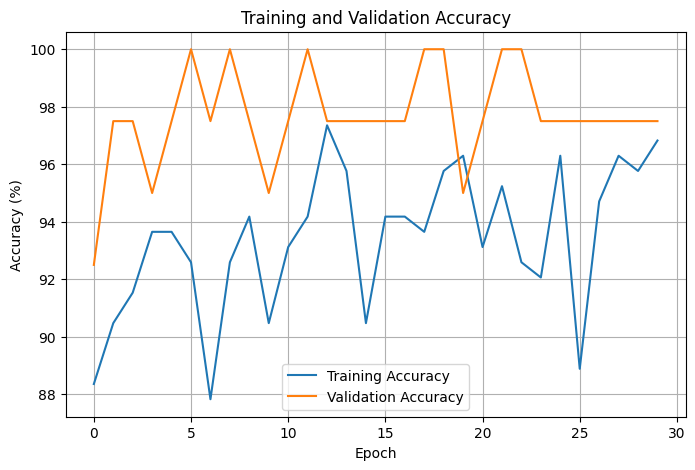

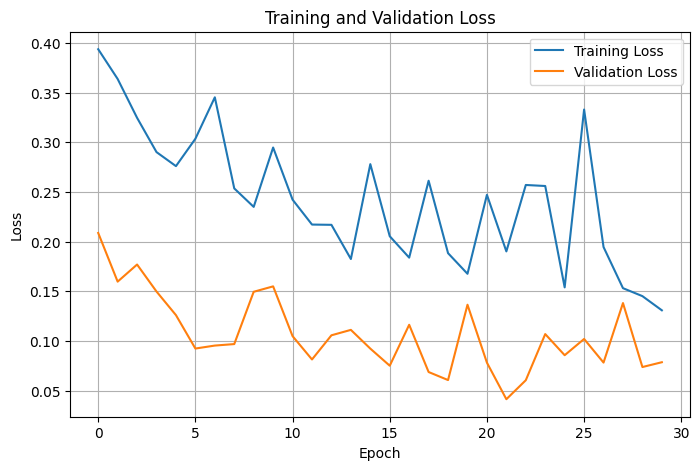

In [ ]:
import matplotlib.pyplot as plt

# Accuracy Graph
plt.figure(figsize=(8, 5))
plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

# Loss Graph
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

In [ ]:
model.eval()

test_correct = 0
test_total = 0
test_loss = 0.0

with torch.no_grad():
    for images, targets in test_loader:

        images = images.to(device)
        targets = targets.to(device)

        outputs = model(images)
        loss = criterion(outputs, targets)

        test_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        test_correct += (predictions == targets).sum().item()
        test_total += targets.size(0)

test_accuracy = (test_correct / test_total) * 100
average_test_loss = test_loss / test_total

print(f"Final Test Accuracy: {test_accuracy:.2f}%")
print(f"Final Test Loss: {average_test_loss:.4f}")

Final Test Accuracy: 100.00%
Final Test Loss: 0.1726


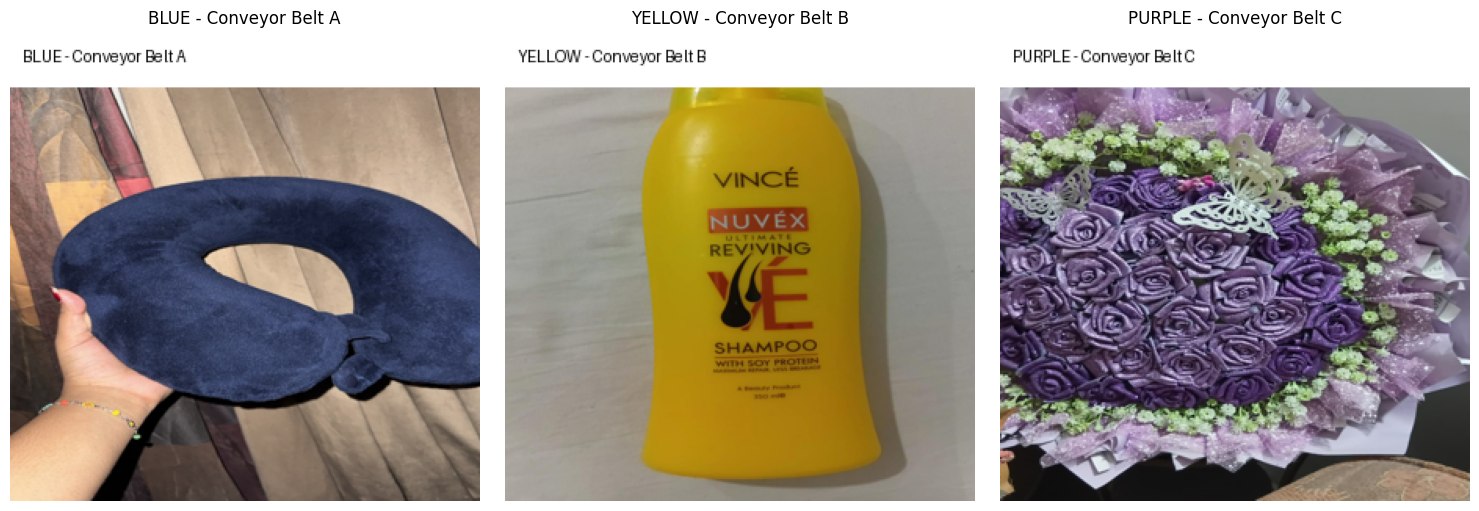

In [ ]:
from PIL import Image, ImageDraw
belt_mapping = {
    "BLUE": "Conveyor Belt A",
    "YELLOW": "Conveyor Belt B",
    "PURPLE": "Conveyor Belt C"
}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, color in zip(axes, ["BLUE", "YELLOW", "PURPLE"]):

    class_index = class_names.index(color)

    image_path, label = next(
        filter(
            lambda item: item[1] == class_index,
            eval_dataset.samples
        )
    )

    image = Image.open(image_path).convert("RGB")
    image = image.resize((300, 300))

    draw = ImageDraw.Draw(image)

    text = f"{color} - {belt_mapping[color]}"

    draw.rectangle((0, 0, 300, 35), fill="white")
    draw.text((8, 10), text, fill="black")

    ax.imshow(image)
    ax.set_title(text)
    ax.axis("off")

plt.tight_layout()
plt.show()

Saving color blue2018.jpg to color blue2018.jpg


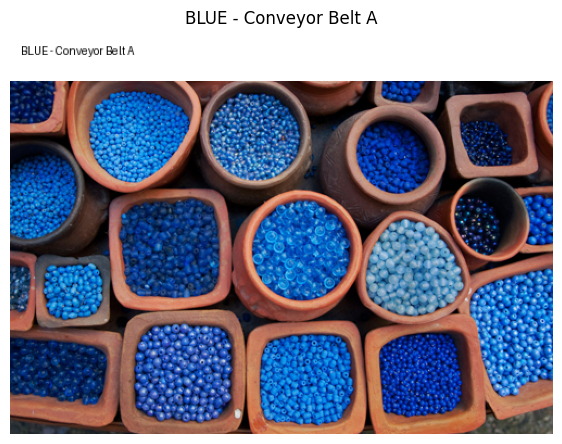

Predicted Color: BLUE
Destination: Conveyor Belt A
Confidence: 100.00%


In [ ]:
from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))
image = Image.open(image_path).convert("RGB")

prediction_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5],
                         [0.5, 0.5, 0.5])
])

image_tensor = prediction_transform(image).unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    output = model(image_tensor)
    probabilities = torch.softmax(output, dim=1)
    confidence, predicted_index = torch.max(probabilities, 1)

predicted_color = class_names[predicted_index.item()]
predicted_belt = belt_mapping[predicted_color]

confidence_score = confidence.item() * 100

display_image = image.copy()
display_image.thumbnail((500, 500))

draw = ImageDraw.Draw(display_image)

label_text = f"{predicted_color} - {predicted_belt}"

draw.rectangle(
    (0, 0, display_image.width, 45),
    fill="white"
)

draw.text((10, 12), label_text, fill="black")

plt.figure(figsize=(7, 6))
plt.imshow(display_image)
plt.title(label_text)
plt.axis("off")
plt.show()

print("Predicted Color:", predicted_color)
print("Destination:", predicted_belt)
print(f"Confidence: {confidence_score:.2f}%")